In [9]:
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

df = pd.read_csv("../data/raw/kredit_sumatera.csv")
df["rasio_angsuran"] = df.angsuran_bulanan / df.penghasilan_bulanan
num = [
    "usia", "tanggungan", "lama_usaha_tahun", "penghasilan_bulanan",
    "ragam_penghasilan", "plafon_diajukan", "tenor_bulan", "bunga_tahunan",
    "rasio_angsuran", "rata_saldo_90h", "jumlah_tunggakan_12b"
]
X = df[num].join(pd.get_dummies(df[["segmen", "wilayah", "kanal"]]))
y = df.gagal_bayar

latih = df.periode <= "2023-12"
model = HistGradientBoostingClassifier(
    max_depth=6, learning_rate=0.06, max_iter=250, random_state=42
).fit(X[latih], y[latih])

baris = []
for periode in sorted(df.loc[df.periode > "2023-12", "periode"].unique()):
    m = df.periode == periode
    baris.append({
        "periode": periode,
        "n": int(m.sum()),
        "auc": roc_auc_score(y[m], model.predict_proba(X[m])[:, 1]),
        "laju_gagal": float(y[m].mean())
    })

hasil = pd.DataFrame(baris)
print(hasil.round(4).to_string(index=False))

periode   n    auc  laju_gagal
2024-01 900 0.7881      0.0911
2024-02 900 0.7183      0.0789
2024-03 900 0.7440      0.0778
2024-04 900 0.7744      0.0789
2024-05 900 0.8122      0.0733
2024-06 900 0.7681      0.1056
2024-07 900 0.7798      0.1100
2024-08 900 0.7560      0.1122
2024-09 900 0.7726      0.1244
2024-10 900 0.7902      0.0978
2024-11 900 0.7525      0.1044
2024-12 900 0.7923      0.1222


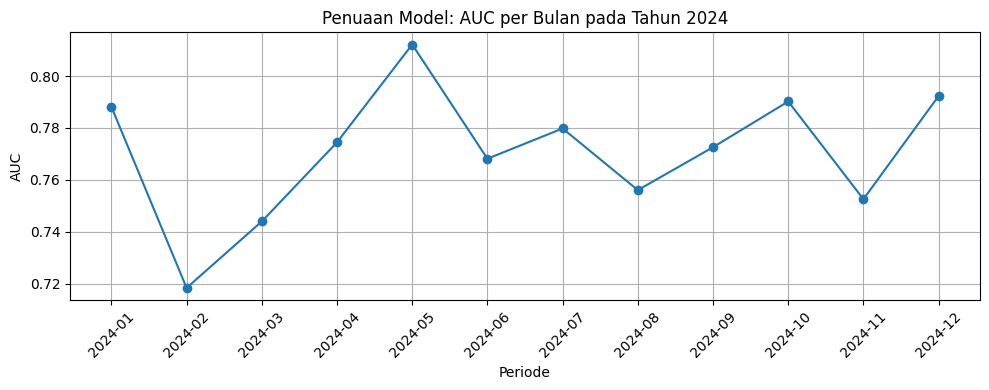

In [10]:
plt.figure(figsize=(10, 4))
plt.plot(hasil["periode"], hasil["auc"], marker="o")
plt.title("Penuaan Model: AUC per Bulan pada Tahun 2024")
plt.xlabel("Periode")
plt.ylabel("AUC")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [11]:
# (a) Apakah komposisi populasi bergeser?
awal = df[df.periode <= "2022-06"]
akhir = df[df.periode >= "2024-07"]
print("Perbandingan Proporsi Segmen (Awal vs Akhir):")
print(pd.DataFrame({
    "awal": awal.segmen.value_counts(normalize=True),
    "akhir": akhir.segmen.value_counts(normalize=True)
}).round(3))

# (b) Kinerja per segmen pada periode uji (> 2024-06)
print("\nAUC per Segmen pada Periode Uji:")
uji = df.periode > "2024-06"
skor = model.predict_proba(X[uji])[:, 1]
for seg, g in df[uji].groupby("segmen"):
    idx = g.index
    s = pd.Series(skor, index=df[uji].index)
    print(f"{seg:<18} n={len(g):5d} auc={roc_auc_score(y.loc[idx], s.loc[idx]):.3f}")

Perbandingan Proporsi Segmen (Awal vs Akhir):
                   awal  akhir
segmen                        
pegawai_tetap     0.414  0.311
wiraswasta        0.251  0.232
pedagang_musiman  0.141  0.179
petani            0.129  0.167
nelayan           0.066  0.111

AUC per Segmen pada Periode Uji:
nelayan            n=  597 auc=0.794
pedagang_musiman   n=  965 auc=0.766
pegawai_tetap      n= 1680 auc=0.784
petani             n=  904 auc=0.705
wiraswasta         n= 1254 auc=0.773


### 1. Hasil Evaluasi Penuaan Model Sepanjang Tahun 2024

Model yang dibekukan menggunakan data pelatihan hingga akhir tahun 2023 (`periode <= "2023-12"`) kemudian diuji secara bulanan sepanjang tahun 2024.

Hasil evaluasi menunjukkan bahwa performa model mengalami fluktuasi selama periode pengujian. Nilai AUC tercatat sebesar `0.7881` pada `2024-01`, kemudian turun menjadi `0.7183` pada `2024-02` dan `0.7440` pada `2024-03`. Model sempat mencapai nilai tertinggi sebesar `0.8122` pada `2024-05`, tetapi kembali mengalami penurunan hingga `0.7525` pada `2024-11`. Fluktuasi tersebut menunjukkan bahwa kemampuan diskriminasi model tidak sepenuhnya stabil ketika diterapkan pada data periode setelah model dibekukan.

Selain perubahan AUC, ditemukan kenaikan laju gagal bayar (*target drift*) pada paruh kedua tahun 2024. Pada periode `2024-06` hingga `2024-12`, laju gagal bayar berada pada kisaran `9,78%–12,44%`, lebih tinggi dibandingkan kisaran pada awal tahun yang berada sekitar `7,33%–9,11%`. Kondisi ini menunjukkan adanya perubahan karakteristik target pada populasi yang dilayani model.

### 2. Analisis Akar Masalah (*Root Cause*): Pergeseran Populasi dan Kinerja per Segmen

Untuk mengetahui penyebab penurunan performa, dilakukan analisis terhadap perubahan komposisi populasi dan kinerja model pada masing-masing segmen. Hasil analisis menunjukkan dua temuan utama.

**1. Pergeseran Komposisi Populasi (*Feature/Covariate Drift*)**

Proporsi nasabah dengan segmen yang relatif lebih stabil, yaitu `pegawai_tetap`, menurun dari **41,4%** pada periode awal menjadi **31,1%** pada periode akhir. Segmen `wiraswasta` juga mengalami penurunan dari **25,1%** menjadi **23,2%**.

Sebaliknya, beberapa segmen dengan karakteristik pendapatan yang lebih musiman atau tidak tetap mengalami peningkatan. Proporsi `pedagang_musiman` meningkat dari **14,1%** menjadi **17,9%**, `petani` dari **12,9%** menjadi **16,7%**, dan `nelayan` dari **6,6%** menjadi **11,1%**. Pergeseran ini menunjukkan bahwa distribusi populasi pada periode pelayanan semakin berbeda dibandingkan populasi yang digunakan saat model dilatih.

**2. Kinerja Terlemah Terpusat pada Segmen Tertentu**

Pada periode uji `> 2024-06`, segmen `petani` menunjukkan kinerja terlemah dengan AUC sebesar **0.705** (`n = 904`). Nilai tersebut lebih rendah dibandingkan `nelayan` (`0.794`), `pegawai_tetap` (`0.784`), `wiraswasta` (`0.773`), dan `pedagang_musiman` (`0.766`).

Dengan demikian, penurunan performa model tidak hanya berkaitan dengan perubahan distribusi populasi secara keseluruhan, tetapi juga dengan ketidakmampuan model mempertahankan kemampuan diskriminasi pada segmen yang proporsinya semakin besar, terutama segmen `petani`.

### 3. Implikasi MLOps

Temuan tersebut menjadi dasar untuk melakukan monitoring drift dan evaluasi performa secara berkala. Jika pola perubahan populasi dan penurunan performa terus berlangsung, model perlu dipertimbangkan untuk menjalani *retraining* menggunakan data yang lebih representatif terhadap populasi terbaru.

Evaluasi berikutnya juga perlu memberikan perhatian khusus terhadap segmen `petani`, baik melalui penambahan data yang representatif maupun evaluasi terhadap fitur dan strategi pembobotan yang sesuai. Namun, keputusan untuk menambah fitur atau memberikan pembobotan khusus perlu diuji lebih lanjut berdasarkan hasil eksperimen berikutnya.

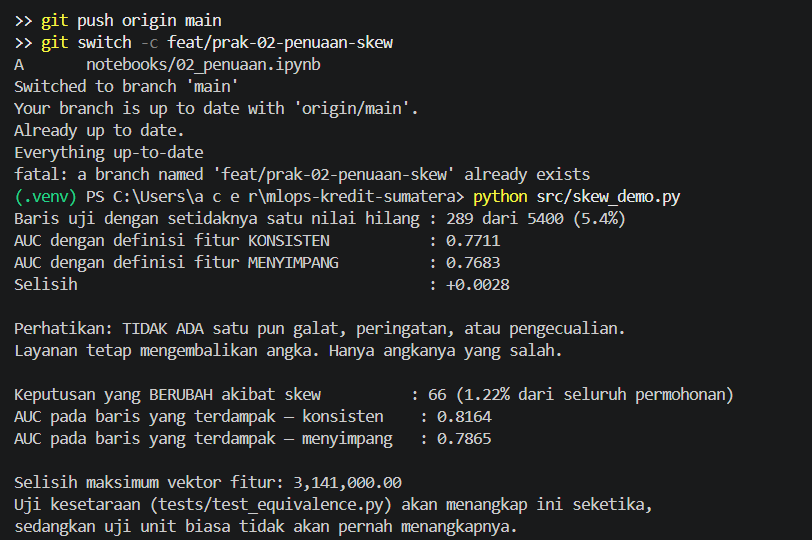

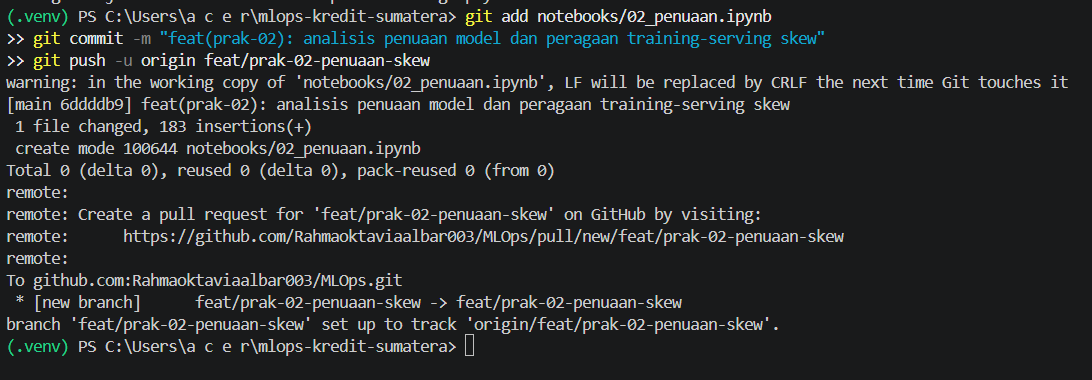

## (a) Grafik Penurunan AUC per Bulan pada Tahun 2024 dan Interpretasinya

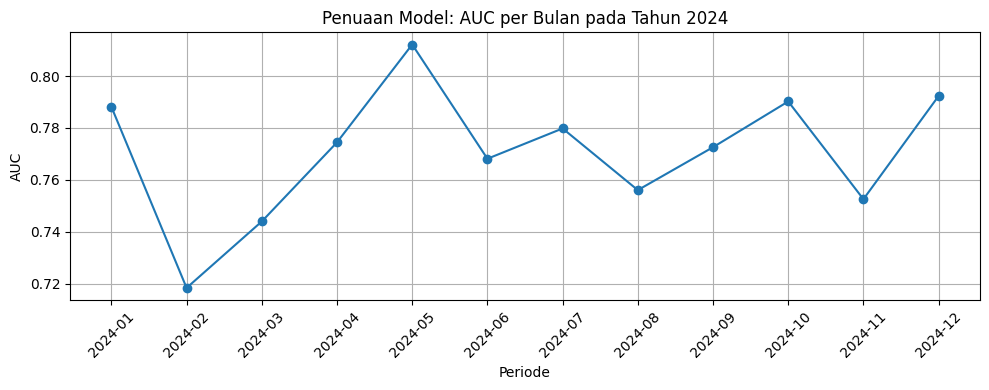

### Tabel Ringkasan Evaluasi Bulanan Model (Dilatih pada Data $\le$ 2023-12)

| Periode | Jumlah Data ($n$) | Skor ROC-AUC | Laju Gagal Bayar |
| :--- | :---: | :---: | :---: |
| 2024-01 | 900 | 0,7881 | 9,11% |
| 2024-02 | 900 | 0,7183 | 7,89% |
| 2024-03 | 900 | 0,7440 | 7,78% |
| 2024-04 | 900 | 0,7744 | 7,89% |
| 2024-05 | 900 | 0,8122 | 7,33% |
| 2024-06 | 900 | 0,7681 | 10,56% |
| 2024-07 | 900 | 0,7798 | 11,00% |
| 2024-08 | 900 | 0,7560 | 11,22% |
| 2024-09 | 900 | 0,7726 | 12,44% |
| 2024-10 | 900 | 0,7902 | 9,78% |
| 2024-11 | 900 | 0,7525 | 10,44% |
| 2024-12 | 900 | 0,7923 | 12,22% |

### Interpretasi
1. Model klasifikasi `HistGradientBoostingClassifier` yang dibekukan pada data pelatihan tahun 2022–2023 mengalami penurunan dan fluktuasi tajam sepanjang tahun 2024. Skor AUC anjlok dari **0,7881** (Januari 2024) menjadi **0,7183** (Februari 2024) dan **0,7440** (Maret 2024), serta kembali merosot ke **0,7560** (Agustus 2024) dan **0,7525** (November 2024).
2. Pada paruh kedua tahun 2024 (mulai Juni hingga Desember 2024), laju gagal bayar aktual melonjak menjadi **9,78%–12,44%** (puncak tertinggi pada September 2024 sebesar 12,44%), meningkat signifikan dibandingkan tingkat gagal bayar historis keseluruhan sebesar 8,30%. Model lama gagal menyesuaikan batas keputusan terhadap perubahan profil risiko ini.

---

## (b) Bukti Pergeseran Komposisi Populasi dan Kaitannya dengan Penurunan Kinerja

Perbandingan distribusi segmen nasabah antara periode awal (`<= 2022-06`) dan periode akhir (`>= 2024-07`) membuktikan adanya **pergeseran fitur/populasi (*feature/covariate drift*)**:

| Segmen Nasabah | Proporsi Awal ($\le$ 2022-06) | Proporsi Akhir ($\ge$ 2024-07) | Perubahan Porsi |
| :--- | :---: | :---: | :---: |
| `pegawai_tetap` | 0,414 (41,4%) | 0,311 (31,1%) | **-10,3%** (Menurun) |
| `wiraswasta` | 0,251 (25,1%) | 0,232 (23,2%) | **-1,9%** (Menurun) |
| `pedagang_musiman` | 0,141 (14,1%) | 0,179 (17,9%) | **+3,8%** (Meningkat) |
| `petani` | 0,129 (12,9%) | 0,167 (16,7%) | **+3,8%** (Meningkat) |
| `nelayan` | 0,066 (6,6%) | 0,111 (11,1%) | **+4,5%** (Meningkat) |

### Kaitan dengan Penurunan Kinerja
Pada masa pelatihan ($\le$ 2023-12), model belajar dari populasi yang didominasi oleh nasabah berpenghasilan tetap dan stabil (`pegawai_tetap` sebesar 41,4%). Namun, pada periode operasional akhir tahun 2024, porsi `pegawai_tetap` menyusut menjadi 31,1%, sedangkan segmen berpendapatan fluktuatif dan berisiko tinggi (`pedagang_musiman`, `petani`, dan `nelayan`) melonjak dari total 33,6% menjadi **45,7%**. Akibatnya, bobot pohon keputusan yang dioptimalkan untuk karakteristik pegawai tetap menjadi kurang akurat saat menilai pola arus kas dan riwayat saldo nasabah sektor informal/musiman, yang juga memiliki proporsi nilai hilang (`rata_saldo_90h`) lebih tinggi.

---

## (c) Analisis Kinerja per Segmen dan Identifikasi Segmen Paling Rawan

Evaluasi terpisah pada periode uji (`> 2024-06`, total 5.400 permohonan) menunjukkan bahwa penurunan kinerja model **tidak merata**, melainkan terpusat pada segmen tertentu:

| Segmen Nasabah | Jumlah Data Uji ($n$) | Skor ROC-AUC Uji | Status Kinerja |
| :--- | :---: | :---: | :--- |
| `nelayan` | 597 | 0,794 | Baik |
| `pegawai_tetap` | 1.680 | 0,784 | Baik |
| `wiraswasta` | 1.254 | 0,773 | Cukup Baik |
| `pedagang_musiman` | 965 | 0,766 | Mulai Menurun |
| **`petani`** | **904** | **0,705** | **Paling Rawan (Terlemah)** |

### Identifikasi Segmen Paling Rawan
Segmen **`petani`** merupakan segmen paling rawan dengan skor **AUC terendah sebesar 0,705** ($n = 904$), terpaut jauh (**-0,079 poin**) dibandingkan segmen `pegawai_tetap` (0,784) maupun `nelayan` (0,794). Karena porsi segmen petani terus bertumbuh (dari 12,9% menjadi 16,7%) sementara kemampuan diskriminasi model pada segmen ini paling lemah, performa agregat portofolio ikut tertekan. Temuan ini memberikan dasar tindak lanjut yang terukur bagi tim MLOps untuk melakukan pelatihan ulang (*retraining*) dengan memperkaya fitur musiman pertanian atau menerapkan kalibrasi ambang batas khusus segmen petani.

---

## (d) Ringkasan Peragaan *Training-Serving Skew* dan Dampak Bisnis Skala Portofolio

Eksekusi skrip `python src/skew_demo.py` memperagakan kegagalan senyap (*silent failure*) ketika kode layanan produksi (*serving*) menulis ulang logika prapemrosesan fitur secara berbeda dari kode pelatihan (*training*): pada pelatihan nilai hilang diisi dengan **median**, sedangkan pada layanan produksi nilai hilang diisi dengan **nol (`0`)**.

* **Keluaran Teknis Peragaan:**
  * Baris uji dengan minimal satu nilai hilang: **289 dari 5.400 permohonan (5,4%)**.
  * AUC definisi fitur **konsisten**: **0,7711** vs AUC definisi fitur **menyimpang**: **0,7683** (selisih agregat hanya **+0,0028**).
  * Pada subset 289 baris yang terdampak nilai hilang, AUC anjlok tajam dari **0,8164** menjadi **0,7865** (turun **-0,0299**).
  * Jumlah keputusan kredit yang **berubah** akibat *skew*: **66 permohonan (1,22% dari seluruh portofolio uji)**.

* **Perhitungan Dampak Bisnis pada Portofolio 200.000 Permohonan/Tahun:**
  $$\text{Keputusan Berubah per Tahun} = \frac{66}{5.400} \times 200.000 = 1,2222\% \times 200.000 \approx \mathbf{2.444\text{ permohonan}}$$
  *(atau sekitar **2.400 keputusan** setiap tahunnya)*.

* **Makna bagi Komite Risiko:**
  Pemantauan metrik agregat semata (selisih AUC 0,0028) membuat kegagalan ini tampak sepele dan tidak memicu pesan galat (*Exception* maupun *log* merah) apa pun di sistem. Namun dalam skala operasional bank dengan 200.000 pemohon per tahun, sekitar **2.400 nasabah nyata** menerima keputusan kredit yang keliru: nasabah layak ditolak (hilangnya potensi pendapatan bunga dan kepercayaan nasabah) atau nasabah berisiko tinggi diluluskan (meningkatkan eksposur kredit macet / *Non-Performing Loan*).

---

## (e) Usulan Arsitektural untuk Mencegah *Training-Serving Skew* Terulang

Untuk mencegah *skew* secara sistemik—tanpa bergantung pada ketelitian atau disiplin manual pengembang dalam menyalin ulang kode—solusi arsitektural yang diusulkan adalah **Penerapan Pustaka Transformasi Fitur Tunggal (*Single-Source Feature Pipeline Artifact*) yang Dibundel Bersama Model**:

1. **Satu Definisi Kode Transformasi (*Single Source of Truth*):** Seluruh logika rekayasa fitur dan imputasi nilai hilang (seperti `SimpleImputer(strategy="median")`, pembentukan `rasio_angsuran`, dan *encoding* kategorikal) dikemas ke dalam satu objek `sklearn.pipeline.Pipeline` atau modul Python tunggal (`src/features.py`) yang dipakai bersama oleh skrip pelatihan dan layanan inferensi (API).
2. **Serialisasi Artefak Terpadu (*Bundled Model Artifact*):** Parameter statistik yang dipelajari saat pelatihan (seperti nilai median tiap kolom) disimpan bersama bobot model ke dalam satu berkas artefak tunggal (misalnya via `joblib` atau `MLflow Model Registry`), sehingga layanan produksi hanya memanggil `pipeline.predict_proba(raw_input)` tanpa pernah menulis ulang logika prapemrosesan secara terpisah.
3. **Pengujian Kontrak Paritas Otomatis pada CI/CD:** Menambahkan pengujian otomatis (*parity test*) di dalam *pipeline* CI yang membandingkan keluaran vektor fitur dari jalur pelatihan dan jalur layanan menggunakan sampel data mentah yang sama (termasuk kasus baris dengan nilai `NaN`), dan secara otomatis memblokir *deployment* apabila ditemukan selisih numerik di luar toleransi.

---

## Catatan Tambahan: Mengapa Uji Unit Biasa Tidak Menangkap *Skew*?

* **Uji unit menguji komponen secara terisolasi, bukan kesamaan lintas lingkungan:** Uji unit pada layanan produksi hanya memverifikasi bahwa fungsi *serving* berjalan tanpa *error* dan mengembalikan tipe keluaran sesuai ekspektasi inputnya sendiri (misalnya memastikan `fillna(0)` mengubah `NaN` menjadi `0`).
* **Tidak ada pembanding terhadap artefak pelatihan:** Karena kode *training* dan kode *serving* ditulis di dua tempat terpisah, uji unit pada masing-masing sisi lulus (*pass*) secara independen karena tidak membandingkan apakah hasil transformasi fitur di *serving* identik dengan hasil transformasi fitur yang diharapkan oleh model saat *training*.